# Audio Autoencoder - Laboratory 4 

## Author: Emiliano Acevedo

In this notebook, we will implement an audio autoencoder using deep learning techniques. An autoencoder is a type of neural network that is trained to compress and reconstruct its input data. It consists of two main parts: an encoder that compresses the input data into a lower-dimensional representation (latent space), and a decoder that reconstructs the original data from this compressed representation. We will use the [MagnaTagATune](https://mirg.city.ac.uk/codeapps/the-magnatagatune-dataset) dataset for this purpose. MagnaTagATune is a dataset containing music clips annotated with various tags, including genres. 

### Import Libraries

In [ ]:
# # Install required packages if not already installed
# %%capture
# !pip install torch torchaudio pandas numpy matplotlib tqdm auraloss torch-audiomentations

In [23]:
import torch
import pandas as pd
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import IPython.display as ipd

from tqdm import tqdm

from torch.utils.data import DataLoader, Dataset
from torchaudio.transforms import MelSpectrogram, Resample
import torchaudio
import auraloss
from torch_audiomentations import (
    Compose,
    Gain,
    AddColoredNoise,
    BandStopFilter,
    PitchShift,
    LowPassFilter,
)


# Set device for computation
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: mps


### Dataset and DataLoader Preparation

I adapted the MagnaTagATune dataset class to be used for autoencoder training. The main changes were:
* Removing the filtering of clips based on genre tags. In this case, we want to use all available clips for training the autoencoder, regardless of their genre tags.
* Adjusting the `__getitem__` method to return a random a random snippet of the audio clip. 

We also add a `subsample_factor` parameter to the dataset class to allow using less data for faster training during experimentation. Given time constraints, I set this factor 0.3 to use 30% of the dataset for training and exploration. At the end, I trained the final model with the full dataset.

In [2]:
class MagnaTagATuneDataset(Dataset):
    
    def __init__(
        self,
        annotation_file_path: str,
        split_file_path: str,
        audio_duration: int = 30,
        sample_rate: int = 16000,
        subsample_factor: float = 1.0,
    ):
        """
        Initialize MagnaTagATune dataset for autoencoder training.
        
        Args:
            annotation_file_path: Path to annotations CSV file with clip metadata and labels.
            split_file_path: Path to TSV file containing clip IDs for train/val/test split.
            audio_duration: Audio clip duration in seconds. Clips are trimmed/padded to this length. Default: 30.
            sample_rate: Target sampling rate in Hz for audio resampling. Default: 16000.
            subsample_factor: Fraction of data to use (0.0 to 1.0). Default: 1.0 (use all data).
        """
        super(MagnaTagATuneDataset, self).__init__()

        # Add audio parameters
        self.audio_duration = audio_duration
        if audio_duration > 30 or audio_duration <= 0:
            raise ValueError("audio_duration must be between 0 and 30 seconds.")
        self.sample_rate = sample_rate
        self.n_samples = sample_rate * audio_duration

        # Load annotations
        self.annotation_df = pd.read_csv(annotation_file_path, sep='\t')

        # Get all tag columns (all columns except clip_id and mp3_path)
        self.TAGS_COLS = [col for col in self.annotation_df.columns if col not in ['clip_id', 'mp3_path']]
        self.n_classes = len(self.TAGS_COLS)

        # Set of file ids for the given split
        df_set = pd.read_csv(split_file_path, sep='\t', header=None)
        self.files_ids = set(df_set[0])

        # Prepare data list, filtering by ids in the split
        self.data = []
        for file_id in self.files_ids:
            row = self.annotation_df[self.annotation_df['clip_id'] == file_id]
            if not row.empty:
                self.data.append(row)

        # Convert list of DataFrames to a single DataFrame
        self.data = pd.concat(self.data, ignore_index=True)
        
        # Subsample data if requested
        if subsample_factor < 1.0:
            if subsample_factor <= 0.0:
                raise ValueError("subsample_factor must be between 0 and 1")
            n_samples = int(len(self.data) * subsample_factor)
            self.data = self.data.sample(n=n_samples, random_state=42).reset_index(drop=True)
            print(f"Subsampled dataset to {n_samples} samples ({subsample_factor*100:.1f}% of original)")

        return

    def __len__(self):
        return len(self.data)
    
    def __get_random_start_end_idx(self, audio_length: int):
        """
        Get random start and end indices for cropping audio to fixed length.
        """
        max_start = audio_length - self.n_samples
        start_idx = torch.randint(0, max_start + 1, (1,)).item()
        end_idx = start_idx + self.n_samples
        return start_idx, end_idx

    def __getitem__(self, idx):
    
        # Get row from dataframe
        row = self.data.iloc[idx]
        
        # Get clip_id and audio path
        clip_id = row['clip_id']
        audio_path = f"./data/mp3/{row['mp3_path']}"
        
        # Load audio
        audio, sr = torchaudio.load(audio_path)
        
        # Resample if necessary
        if sr != self.sample_rate:
            resampler = Resample(orig_freq=sr, new_freq=self.sample_rate)
            audio = resampler(audio)
        
        # Convert stereo to mono if necessary
        if audio.shape[0] > 1:
            audio = torch.mean(audio, dim=0, keepdim=True)
        
        start_idx, end_idx = self.__get_random_start_end_idx(audio.shape[1])
        audio = audio[:, start_idx:end_idx]
        
        # Pad if too short
        if audio.shape[1] < self.n_samples:
            pad_size = self.n_samples - audio.shape[1]
            audio = torch.cat([audio, torch.zeros(1, pad_size)], dim=1)
        
        # Squeeze to 1D tensor
        audio = audio.squeeze(0)
        
        # Get labels as binary vector
        labels = torch.tensor(
            row[self.TAGS_COLS].values.astype(np.float32), dtype=torch.float32
        )
        
        return {
            "audio": audio,
            "labels": labels,
            "clip_id": clip_id
        }
        

Following class example we will use `AUDIO_DURATION = 1` second for the audio snippets and original sampling rate of `SAMPLE_RATE = 16000` Hz.



In [3]:
AUDIO_DURATION = 1  # seconds
SAMPLE_RATE = 16000  # Hz

train_dataset = MagnaTagATuneDataset(
    annotation_file_path='./data/annotations_final.csv',
    split_file_path='./data/train_gt_mtt.tsv',
    audio_duration=AUDIO_DURATION,
    sample_rate=SAMPLE_RATE,
    subsample_factor=0.3
)
val_dataset = MagnaTagATuneDataset(
    annotation_file_path='./data/annotations_final.csv',
    split_file_path='./data/val_gt_mtt.tsv',
    audio_duration=AUDIO_DURATION,
    sample_rate=SAMPLE_RATE
)
test_dataset = MagnaTagATuneDataset(
    annotation_file_path='./data/annotations_final.csv',
    split_file_path='./data/test_gt_mtt.tsv',
    audio_duration=AUDIO_DURATION,
    sample_rate=SAMPLE_RATE
)

train_loader = DataLoader(
    train_dataset, 
    batch_size=128,
    shuffle=True,
    # num_workers=0,  # Set to 0 for Jupyter notebooks
    # pin_memory=True # Not working on MPS
)
val_loader = DataLoader(
    val_dataset, 
    batch_size=128, 
    shuffle=False
)
test_loader = DataLoader(
    test_dataset, 
    batch_size=128,
    shuffle=False
)

Subsampled dataset to 5611 samples (30.0% of original)


## Agumentation Pipeline

We define an augmentation pipeline as well, similar to the one used in the class example. The augmentations include random Gain, BandStop, PitchShift, ColorNoise, and LowPass filters. These augmentations we will used to try to make the autoencoder more robust in the latent space representation, and hence in the reconstruction of the audio clips.

In [50]:
class AugmentationChain(nn.Module):
    """Add a number of audio augmentaitons with probability p."""

    p = 0.75
    sr = 16000
    def __init__(self, **kwargs):
        super().__init__()
        self.chain = Compose(
            transforms=[
                Gain(p=self.p, output_type='tensor'),
                BandStopFilter(sample_rate=self.sr, p=self.p, output_type='tensor'),
                PitchShift(p=self.p, sample_rate=self.sr, output_type='tensor'),
                AddColoredNoise(p=self.p, output_type='tensor'),
                LowPassFilter(p=self.p, sample_rate=self.sr, min_cutoff_freq=400, output_type='tensor',),
            ]
            , output_type='tensor'
        )

    def forward(self, audio):
        return self.chain(audio.unsqueeze(1)).squeeze(1)

## Define the Autoencoder Model

In order to start the implementation of the autoencoder, we will define the architecture of the encoder and decoder networks presented in the class example. The encoder will consist of several convolutional layers followed by fully connected layers to compress the input audio into a lower-dimensional latent space. The decoder will mirror the encoder architecture, using transposed convolutional layers to reconstruct the audio from the latent representation.

In [5]:
class AudioAutoencoder(nn.Module):
    """A more capable audio autoencoder featuring batch-norm, PReLu activations,
    and sharedd indices for the downsampling and upsampling layers.
    """
    def __init__(
        self,
        input_length=16000,
        bottleneck_size=64,
        kernel_size=5,
        channels=8,
        channel_mult=2,
        downsample=4,
    ):
        super().__init__()
        assert kernel_size % 2 == 1, "kernel_size should be odd for same padding"

        padding = kernel_size // 2

        # ----- Encoder -----
        self.enc_conv1 = nn.Conv1d(1, channels, kernel_size=kernel_size, padding=padding)
        self.enc_norm1 = nn.BatchNorm1d(channels)
        self.enc_act1 = nn.PReLU()
        self.pool1 = nn.MaxPool1d(2, stride=downsample, return_indices=True)

        self.enc_conv2 = nn.Conv1d(channels, channels * channel_mult, kernel_size=kernel_size, padding=padding)
        self.enc_norm2 = nn.BatchNorm1d(channels * channel_mult)
        self.enc_act2 = nn.PReLU()
        self.pool2 = nn.MaxPool1d(2, stride=downsample, return_indices=True)

        self.enc_conv3 = nn.Conv1d(channels * channel_mult, channels * channel_mult ** 2, kernel_size=kernel_size, padding=padding)
        self.enc_norm3 = nn.BatchNorm1d(channels * channel_mult ** 2)
        self.enc_act3 = nn.PReLU()
        self.pool3 = nn.MaxPool1d(2, stride=downsample, return_indices=True)

        enc_out_len = input_length // downsample ** 3 * channels * channel_mult ** 2  # 3× pooling halves length thrice
        self.enc_fc = nn.Linear(enc_out_len, bottleneck_size)

        comp_rate =  input_length / bottleneck_size
        print(f"Compression rate: {comp_rate:.1f}X")

        # ----- Decoder -----
        self.dec_fc = nn.Linear(bottleneck_size, enc_out_len)

        self.unpool3 = nn.MaxUnpool1d(2, stride=downsample)
        self.dec_deconv3 = nn.Conv1d(channels * channel_mult ** 2, channels * channel_mult, kernel_size=kernel_size, padding=padding)
        self.dec_act3 = nn.PReLU()

        self.unpool2 = nn.MaxUnpool1d(2, stride=downsample)
        self.dec_deconv2 = nn.Conv1d(channels * channel_mult, channels, kernel_size=kernel_size, padding=padding)
        self.dec_act2 = nn.PReLU()

        self.unpool1 = nn.MaxUnpool1d(2, stride=downsample)
        self.dec_deconv1 = nn.Conv1d(channels, 1, kernel_size=kernel_size, padding=padding)
        self.dec_tanh = nn.Tanh()

    def encoder(self, x):
        sizes, indices = [], []

        x = self.enc_act1(self.enc_norm1(self.enc_conv1(x)))
        sizes.append(x.size())
        x, idx1 = self.pool1(x)
        indices.append(idx1)

        x = self.enc_act2(self.enc_norm2(self.enc_conv2(x)))
        sizes.append(x.size())
        x, idx2 = self.pool2(x)
        indices.append(idx2)

        x = self.enc_act3(self.enc_norm3(self.enc_conv3(x)))
        sizes.append(x.size())
        x, idx3 = self.pool3(x)
        indices.append(idx3)
        x = x.flatten(start_dim=1)

        x = self.enc_fc(x)
        return x, indices, sizes

    # ----- Decoder -----
    def decoder(self, z, indices, sizes):
        idx1, idx2, idx3 = indices
        size1, size2, size3 = sizes

        x = self.dec_fc(z)
        x = x.view(size3[0], size3[1], -1)

        x = self.unpool3(x, idx3, output_size=size3)
        x = self.dec_act3(self.dec_deconv3(x))

        x = self.unpool2(x, idx2, output_size=size2)
        x = self.dec_act2(self.dec_deconv2(x))

        x = self.unpool1(x, idx1, output_size=size1)
        x = self.dec_tanh(self.dec_deconv1(x))

        return x

    # ----- Forward -----
    def forward(self, x):
        z, indices, sizes = self.encoder(x)
        x_r = self.decoder(z, indices, sizes)
        return x_r, z

## Define Perceptual Loss

To train the autoencoder, we will start using Mean Squared Error (MSE) loss between the input and reconstructed audio. However, to improve the quality of the reconstructed audio, we will implement a perceptual loss function. 

In [6]:
def multi_scale_stft_loss(x, y, scales=[512, 1024, 2048], hop_ratio=0.25):
    """Simple implementation of the multi-scale STFT loss.
    https://arxiv.org/pdf/1910.11480
    """
    loss = 0
    for n_fft in scales:
        hop = int(n_fft * hop_ratio)
        window = torch.hann_window(n_fft, device=x.device)
        X = torch.stft(x.squeeze(), n_fft=n_fft, hop_length=hop, window=window, return_complex=True)
        Y = torch.stft(y.squeeze(), n_fft=n_fft, hop_length=hop, window=window, return_complex=True)
        loss += torch.mean(torch.abs(X.abs() - Y.abs()))
    return loss / len(scales)

We will also explore using the `auraloss` [library](https://github.com/csteinmetz1/auraloss), which provides several perceptual loss functions specifically designed for audio signals. In particular, we will use their Multi-Resolution STFT Loss with perceptual weighting and mel-scaled spectrograms, which offers a more sophisticated alternative to our custom implementation:

In [7]:
## Example of using auraloss -- Example extracted from the auraloss Github
bs = 8
chs = 1
seq_len = 131072
sample_rate = 44100

# some audio you want to compare
target = torch.rand(bs, chs, seq_len)
pred = torch.rand(bs, chs, seq_len)

# define the loss function
loss_fn = auraloss.freq.MultiResolutionSTFTLoss(
    fft_sizes=[1024, 2048, 8192],
    hop_sizes=[256, 512, 2048],
    win_lengths=[1024, 2048, 8192],
    scale="mel",
    n_bins=128,
    sample_rate=sample_rate,
    perceptual_weighting=True, # enable perceptual weighting
)

# compute
loss = loss_fn(pred, target)
print(f"Loss: {loss.item():.6f}")

Loss: 0.701559


## Define Training and Evaluation Loop

Now, we will first define the the training loop for a baseline autoencoder using MSE loss, and then modify it to incorporate some improvements. The training loop will involve iterating over the training dataset, passing the data through the autoencoder, computing the loss, and updating the model weights using backpropagation. We will also implement an evaluation loop to assess the performance of the autoencoder on a validation dataset after each epoch in order to monitor its progress and save the best model based on validation loss.

In [8]:
def train_baseline_autoencoder(
    model,
    device,
    train_loader,
    val_loader,
    num_epochs=20,
    learning_rate=1e-3,
    loss_type='mse', # or "multi_scale_stft_loss"
    save_best_model=True,
    checkpoint_path='best_autoencoder.pth'
):
    """
    Train the baseline audio autoencoder with specified loss function.

    :param model: AudioAutoencoder model to train.
    :param device: Device to use for training (MPS, CPU, or GPU).
    :param train_loader: DataLoader for training data.
    :param val_loader: DataLoader for validation data.
    :param num_epochs: Number of training epochs.
    :param learning_rate: Learning rate for the optimizer.
    :param loss_type: Type of loss function to use ('mse' or 'multi_scale_stft_loss').
    :param save_best_model: Whether to save the best model based on validation loss.
    :param checkpoint_path: Path to save the best model checkpoint.

    :return: history dictionary with training and validation losses.
    """
    
    # Move model to device
    model.to(device)
    
    # Initialize optimizer
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    
    # Define loss function
    mse_criterion = nn.MSELoss()

    # Intialize history
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_mse": [],
        "train_perceptual": [],
        "val_mse": [],
        "val_perceptual": []
    }

    # Track best validation loss for model saving
    best_val_loss = float('inf')
    best_epoch = 0

    for epoch in range(num_epochs):
        model.train()
        train_losses = []
        train_mse_losses = []
        train_perceptual_losses = []

        train_iter = iter(train_loader)
        train_pbar = tqdm(range(len(train_loader)), desc=f'Epoch {epoch+1}/{num_epochs} [Train]')
        for i in train_pbar:
            # Get batch
            batch = next(train_iter)
            audio = batch['audio'].to(device)

            # Optimization step
            optimizer.zero_grad()

            # Forward pass
            recon_audio, _ = model(audio.unsqueeze(1))
            recon_audio = recon_audio.squeeze(1)
            
            # Calculate losses based on loss_type
            if loss_type == 'mse':
                loss = mse_criterion(recon_audio, audio)
                mse_loss = loss.item()
                perceptual_loss = 0.0
            elif loss_type == 'perceptual':
                loss = multi_scale_stft_loss(recon_audio, audio)
                mse_loss = 0.0
                perceptual_loss = loss.item()
            else:
                raise ValueError(f"Invalid loss_type: {loss_type}. Must be 'mse' or 'perceptual'")
            
            # Backward pass and optimization
            loss.backward()
            optimizer.step()

            # Record losses
            train_losses.append(loss.item())
            train_mse_losses.append(mse_loss)
            train_perceptual_losses.append(perceptual_loss)
            
            # Update progress bar
            train_pbar.set_postfix({'loss': f'{loss.item():.4f}'})

        avg_train_loss = np.mean(train_losses)
        history['train_loss'].append(avg_train_loss)
        history['train_mse'].append(np.mean(train_mse_losses))
        history['train_perceptual'].append(np.mean(train_perceptual_losses))

        # Validation
        model.eval()
        val_losses = []
        val_mse_losses = []
        val_perceptual_losses = []

        with torch.no_grad():
            val_iter = iter(val_loader)
            val_pbar = tqdm(range(len(val_loader)), desc=f'Epoch {epoch+1}/{num_epochs} [Val]')
            for i in val_pbar:
                # Get batch
                batch = next(val_iter)
                audio = batch['audio'].to(device)
                
                # Forward pass
                recon_audio, _ = model(audio.unsqueeze(1))
                recon_audio = recon_audio.squeeze(1)
                
                # Always calculate both losses for monitoring
                mse_loss_val = mse_criterion(recon_audio, audio)
                perceptual_loss_val = multi_scale_stft_loss(recon_audio, audio)
                
                # Select which loss to use for model selection based on loss_type
                if loss_type == 'mse':
                    loss = mse_loss_val
                elif loss_type == 'perceptual':
                    loss = perceptual_loss_val
                else:
                    raise ValueError(f"Invalid loss_type: {loss_type}. Must be 'mse' or 'perceptual'")

                val_losses.append(loss.item())
                val_mse_losses.append(mse_loss_val.item())
                val_perceptual_losses.append(perceptual_loss_val.item())
                
                # Update progress bar
                val_pbar.set_postfix({'loss': f'{loss.item():.4f}'})

        avg_val_loss = np.mean(val_losses)
        history['val_loss'].append(avg_val_loss)
        history['val_mse'].append(np.mean(val_mse_losses))
        history['val_perceptual'].append(np.mean(val_perceptual_losses))
        
        # Save best model based on validation loss
        if save_best_model and avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            best_epoch = epoch + 1
            torch.save({
                'epoch': epoch + 1,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'val_loss': avg_val_loss,
                'train_loss': avg_train_loss,
                'history': history,
                'config': {
                    'loss_type': loss_type,
                    'learning_rate': learning_rate
                }
            }, checkpoint_path)
            print(f'\n[Epoch {epoch+1}] Saved best model (val_loss: {avg_val_loss:.6f})')
    
    if save_best_model:
        print(f'\nTraining completed! Best model from epoch {best_epoch} with val_loss: {best_val_loss:.6f}')
        print(f'Model saved to: {checkpoint_path}')

    return history

In [73]:
def load_checkpoint(model, checkpoint_path, device):
    """
    Load a saved model checkpoint.
    
    Args:
        model: The model instance to load weights into
        checkpoint_path: Path to the checkpoint file
        device: Device to load the model onto
        
    Returns:
        Tuple of (model, checkpoint_info)
    """
    # Use weights_only=False since the checkpoint contains numpy objects and history dict
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
    model.load_state_dict(checkpoint['model_state_dict'])
    model.to(device)
    
    print(f"Loaded checkpoint from epoch {checkpoint['epoch']}")
    print(f"Training loss: {checkpoint['train_loss']:.6f}")
    print(f"Validation loss: {checkpoint['val_loss']:.6f}")
    if 'config' in checkpoint:
        print(f"Model configuration: {checkpoint['config']}")
    
    return model, checkpoint

## Auxiliary Functions

Auxiliary functions for plotting loss curves and listening to original and reconstructed audio samples will also be implemented to facilitate the evaluation of the autoencoder's performance.

In [19]:
def plot_loss_and_metrics(history, loss_type='mse'):
    """
    Plot training and validation losses, and print best model metrics.
    
    Args:
        history: Dictionary containing training history with keys:
                 'train_loss', 'val_loss', 'train_mse', 'train_perceptual',
                 'val_mse', 'val_perceptual'
        loss_type: Type of loss used during training ('mse' or 'perceptual')
    """
    epochs = range(1, len(history['train_loss']) + 1)
    
    # Plot only the main training/validation loss
    fig, ax = plt.subplots(1, 1, figsize=(8, 5), dpi =300)
    
    ax.plot(epochs, history['train_loss'], 'b-', label='Train', linewidth=2, marker='o', markersize=4)
    ax.plot(epochs, history['val_loss'], 'r-', label='Validation', linewidth=2, marker='s', markersize=4)
    ax.set_xlabel('Epoch', fontsize=12)
    ax.set_ylabel('Loss', fontsize=12)
    
    if loss_type == 'mse':
        title = 'MSE Loss'
    elif loss_type == 'perceptual':
        title = 'Perceptual Loss (Multi-Scale STFT)'
    else:
        title = 'Training Loss'
        
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.legend(fontsize=11)
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Print best model metrics only
    best_epoch = np.argmin(history['val_loss']) + 1
    best_idx = best_epoch - 1
    
    print("="*60)
    print(f"BEST MODEL (Epoch {best_epoch})")
    print("="*60)
    print(f"  Train Loss: {history['train_loss'][best_idx]:.6f}")
    print(f"  Val Loss:   {history['val_loss'][best_idx]:.6f}")
    print(f"  Train MSE:  {history['train_mse'][best_idx]:.6f}")
    print(f"  Val MSE:    {history['val_mse'][best_idx]:.6f}")
    print(f"  Train Perceptual: {history['train_perceptual'][best_idx]:.6f}")
    print(f"  Val Perceptual:   {history['val_perceptual'][best_idx]:.6f}")
    
    # Improvement metrics
    improvement = ((history['val_loss'][0] - history['val_loss'][best_idx]) / history['val_loss'][0]) * 100
    print(f"\n  Improvement from initial: {improvement:.2f}%")
    print("="*60)

In [27]:
def display_audio_comparisons(model, data_loader, device, sample_rate=16000, n_samples=5):
    """
    Display and play original vs reconstructed audio for comparison.
    
    Args:
        model: Trained autoencoder model
        data_loader: DataLoader to get audio samples from
        device: Device to run model on
        sample_rate: Sample rate of audio (default: 16000 Hz)
        n_samples: Number of audio samples to display (default: 5)
    """
    
    model.eval()
    model.to(device)
    
    # Get a batch of samples
    batch = next(iter(data_loader))
    # take random n_samples from the batch
    indices = torch.randperm(len(batch['audio']))[:n_samples]
    audio_batch = batch['audio'][indices].to(device)
    clip_ids = batch['clip_id'][indices]
    
    # Generate reconstructions
    with torch.no_grad():
        recon_batch, _ = model(audio_batch.unsqueeze(1))
        recon_batch = recon_batch.squeeze(1).cpu()
    
    audio_batch = audio_batch.cpu()
    
    # Display each pair
    for i in range(n_samples):
        print("=" * 80)
        print(f"Sample {i+1}/{n_samples} - Clip ID: {clip_ids[i]}")
        print("=" * 80)
        
        print("\n🎵 Original Audio:")
        display(ipd.Audio(audio_batch[i].numpy(), rate=sample_rate))
        
        print("\n🔄 Reconstructed Audio:")
        display(ipd.Audio(recon_batch[i].numpy(), rate=sample_rate))
        
        print("\n")
    
    print("=" * 80)
    print(f"Displayed {n_samples} audio comparisons")
    print("=" * 80)

## Baseline Autoencoder Training with MSE Loss

In [10]:
model = AudioAutoencoder(
    input_length=train_dataset.n_samples, 
    bottleneck_size=512, 
    downsample=2)

# Example 1: MSE loss only (default)
history = train_baseline_autoencoder(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    device=device,
    num_epochs=20,
    learning_rate=1e-3,
    loss_type='mse',
    save_best_model=True,
    checkpoint_path='baseline_mse.pth'
)

Compression rate: 31.2X


Epoch 1/20 [Val]: 100%|██████████| 15/15 [00:13<00:00,  1.10it/s, loss=0.0244]




[Epoch 1] Saved best model (val_loss: 0.026864)


Epoch 2/20 [Val]: 100%|██████████| 15/15 [00:13<00:00,  1.11it/s, loss=0.0176]




[Epoch 2] Saved best model (val_loss: 0.018829)


Epoch 3/20 [Val]: 100%|██████████| 15/15 [00:13<00:00,  1.11it/s, loss=0.0126]



... (27 outputs left out)

Epoch 18/20 [Val]: 100%|██████████| 15/15 [00:13<00:00,  1.09it/s, loss=0.0030]




[Epoch 18] Saved best model (val_loss: 0.003098)


Epoch 20/20 [Val]: 100%|██████████| 15/15 [00:13<00:00,  1.11it/s, loss=0.0027]




[Epoch 20] Saved best model (val_loss: 0.003065)

Training completed! Best model from epoch 20 with val_loss: 0.003065
Model saved to: baseline_mse.pth


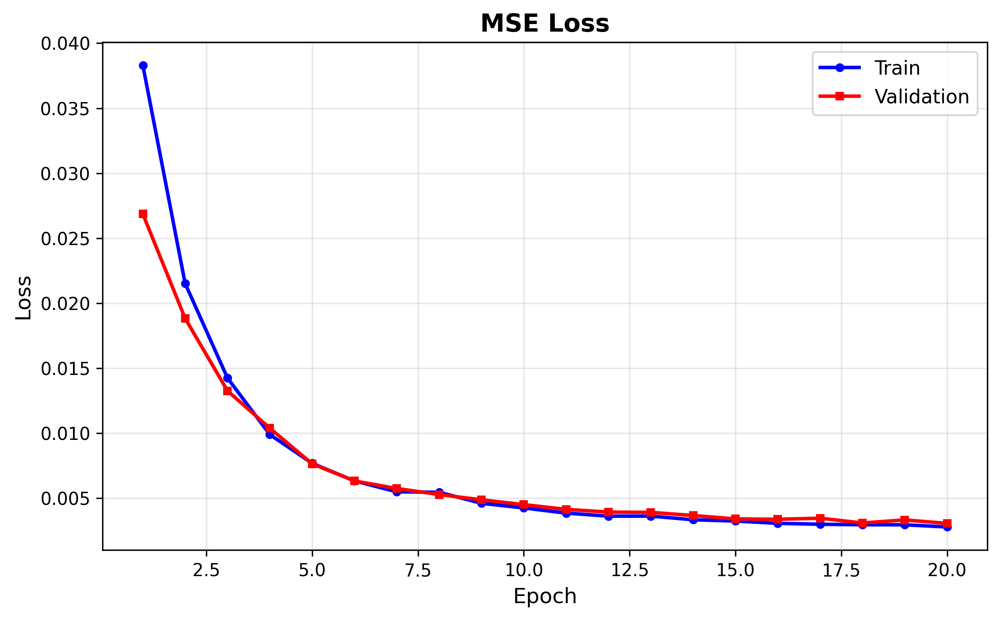

BEST MODEL (Epoch 20)
  Train Loss: 0.002791
  Val Loss:   0.003065
  Train MSE:  0.002791
  Val MSE:    0.003065
  Train Perceptual: 0.000000
  Val Perceptual:   0.454024

  Improvement from initial: 88.59%


In [20]:
plot_loss_and_metrics(history, loss_type='mse')

In [21]:
model = AudioAutoencoder(
    input_length=train_dataset.n_samples, 
    bottleneck_size=512, 
    downsample=2)

# Example 2: Perceptual loss only
history = train_baseline_autoencoder(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    device=device,
    num_epochs=20,
    learning_rate=1e-3,
    loss_type='perceptual',
    save_best_model=True,
    checkpoint_path='baseline_perceptual.pth'
)

Compression rate: 31.2X


Epoch 1/20 [Val]: 100%|██████████| 15/15 [00:13<00:00,  1.09it/s, loss=0.6828]




[Epoch 1] Saved best model (val_loss: 0.756382)


Epoch 2/20 [Val]: 100%|██████████| 15/15 [00:13<00:00,  1.12it/s, loss=0.6062]




[Epoch 2] Saved best model (val_loss: 0.655699)


Epoch 3/20 [Val]: 100%|██████████| 15/15 [00:14<00:00,  1.06it/s, loss=0.5890]



... (25 outputs left out)

Epoch 19/20 [Val]: 100%|██████████| 15/15 [00:14<00:00,  1.04it/s, loss=0.3736]



[Epoch 19] Saved best model (val_loss: 0.383386)


Epoch 20/20 [Val]: 100%|██████████| 15/15 [00:13<00:00,  1.11it/s, loss=0.3944]




[Epoch 20] Saved best model (val_loss: 0.379256)

Training completed! Best model from epoch 20 with val_loss: 0.379256
Model saved to: baseline_perceptual.pth


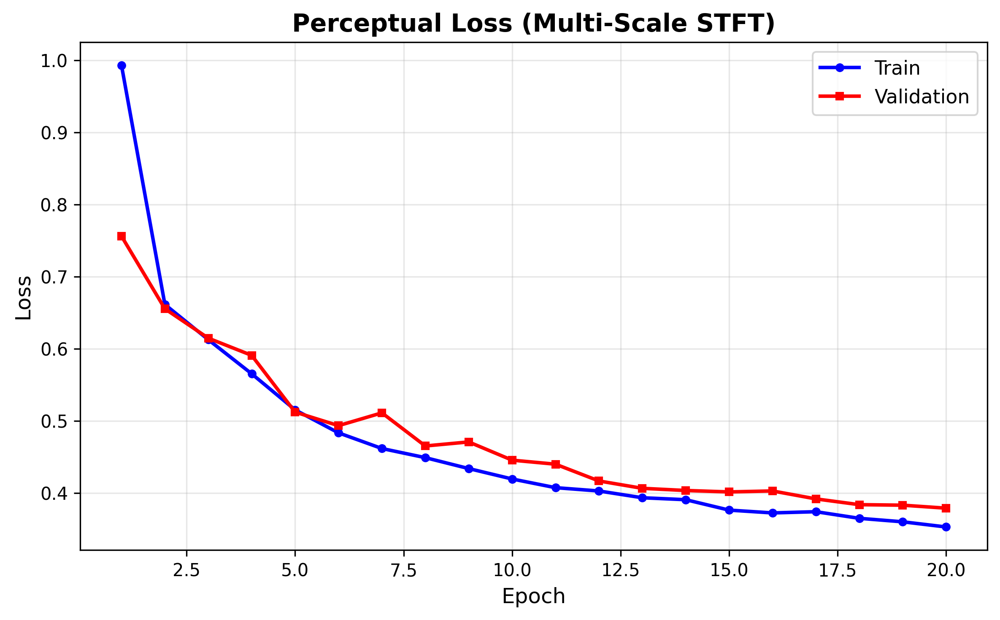

BEST MODEL (Epoch 20)
  Train Loss: 0.353190
  Val Loss:   0.379256
  Train MSE:  0.000000
  Val MSE:    0.076250
  Train Perceptual: 0.353190
  Val Perceptual:   0.379256

  Improvement from initial: 49.86%


In [22]:
plot_loss_and_metrics(history, loss_type='perceptual')

In [31]:
# Comare audio reconstructions from both models
# Load best MSE model
model, checkpoint = load_checkpoint(model, 'baseline_mse.pth', device)
print("\n--- Audio Reconstructions from MSE-trained Model ---\n")
display_audio_comparisons(model, test_loader, device, sample_rate=SAMPLE_RATE, n_samples=4)


# Load best Perceptual model
model, checkpoint = load_checkpoint(model, 'baseline_perceptual.pth', device)
print("\n--- Audio Reconstructions from Perceptual-trained Model ---\n")
display_audio_comparisons(model, test_loader, device, sample_rate=SAMPLE_RATE, n_samples=4)

Loaded checkpoint from epoch 20
Training loss: 0.002791
Validation loss: 0.003065
Model configuration: {'loss_type': 'mse', 'learning_rate': 0.001}

--- Audio Reconstructions from MSE-trained Model ---

Sample 1/4 - Clip ID: 32829

🎵 Original Audio:
Sample 1/4 - Clip ID: 32829

🎵 Original Audio:



🔄 Reconstructed Audio:




Sample 2/4 - Clip ID: 485

🎵 Original Audio:



🔄 Reconstructed Audio:




Sample 3/4 - Clip ID: 32994

🎵 Original Audio:



🔄 Reconstructed Audio:


... (7 outputs left out)


🔄 Reconstructed Audio:




Sample 4/4 - Clip ID: 504

🎵 Original Audio:



🔄 Reconstructed Audio:




Displayed 4 audio comparisons


**Comment:** Two baseline autoencoder were trained for 20 epochs using MSE loss and Perceptual Loss respectively. Both models used the same architecture and training parameters for a fair comparison. Both models converged, not significantly overfitting given the training curves. We see that still there is room for improvement if we use more epochs and/or a larger model capacity.

Beside the first autoencoder trained with MSE loss, have a better reconstruction in terms of MSE audio metric, perceptual quality of the reconstructed audio is poor we hear noise and artifacts in the reconstructed audio.

On the other hand, the second autoencoder trained with Perceptual Loss produces reconstructions with better perceptual quality of the reconstructed audio, besides having a worse MSE metric compared to the first model.

For instance, after seeing and listening to the results of both models, I would propose some improvements:

* Use data augmentation during training to make the model more robust to variations in the audio signal.
* Due to the importance of perceptual loss in audio quality, I would focus on improving the perceptual loss function. I will use the `auraloss` library's Multi-Resolution STFT Loss with perceptual weighting and mel-scaled spectrograms and try to combine it also with MSE loss to have a better balance between signal fidelity and perceptual quality.
* Increase the model capacity by adding more layers or increasing the number of filters in the convolutional layers to allow the model to learn more complex representations of the audio data.

I will explore this combination of improvements in the next section.

## Improved Autoencoder 

Implementation of an enhanced audio autoencoder architecture featuring five convolutional layers in both the encoder and decoder, two more layers than the baseline model.

In [43]:
class ImprovedAudioAutoencoder(nn.Module):
    """An improved audio autoencoder with 5 convolutional layers in encoder and decoder."""
    def __init__(
        self,
        input_length=16000,
        bottleneck_size=64,
        kernel_size=5,
        channels=8,
        channel_mult=2,
        downsample=4,
    ):
        super().__init__()
        assert kernel_size % 2 == 1, "kernel_size should be odd for same padding"

        padding = kernel_size // 2

        # ----- Encoder (5 layers) -----
        self.enc_conv1 = nn.Conv1d(1, channels, kernel_size=kernel_size, padding=padding)
        self.enc_norm1 = nn.BatchNorm1d(channels)
        self.enc_act1 = nn.PReLU()
        self.pool1 = nn.MaxPool1d(2, stride=downsample, return_indices=True)

        self.enc_conv2 = nn.Conv1d(channels, channels * channel_mult, kernel_size=kernel_size, padding=padding)
        self.enc_norm2 = nn.BatchNorm1d(channels * channel_mult)
        self.enc_act2 = nn.PReLU()
        self.pool2 = nn.MaxPool1d(2, stride=downsample, return_indices=True)

        self.enc_conv3 = nn.Conv1d(channels * channel_mult, channels * channel_mult ** 2, kernel_size=kernel_size, padding=padding)
        self.enc_norm3 = nn.BatchNorm1d(channels * channel_mult ** 2)
        self.enc_act3 = nn.PReLU()
        self.pool3 = nn.MaxPool1d(2, stride=downsample, return_indices=True)

        # New layer 4
        self.enc_conv4 = nn.Conv1d(channels * channel_mult ** 2, channels * channel_mult ** 3, kernel_size=kernel_size, padding=padding)
        self.enc_norm4 = nn.BatchNorm1d(channels * channel_mult ** 3)
        self.enc_act4 = nn.PReLU()
        self.pool4 = nn.MaxPool1d(2, stride=downsample, return_indices=True)

        # New layer 5
        self.enc_conv5 = nn.Conv1d(channels * channel_mult ** 3, channels * channel_mult ** 4, kernel_size=kernel_size, padding=padding)
        self.enc_norm5 = nn.BatchNorm1d(channels * channel_mult ** 4)
        self.enc_act5 = nn.PReLU()
        self.pool5 = nn.MaxPool1d(2, stride=downsample, return_indices=True)

        # Calculate flattened size after 5 pooling layers
        enc_out_len = input_length // downsample ** 5 * channels * channel_mult ** 4
        self.enc_fc = nn.Linear(enc_out_len, bottleneck_size)

        comp_rate = input_length / bottleneck_size
        print(f"Compression rate: {comp_rate:.1f}X")
        print(f"Architecture: 5 encoder layers, {channels * channel_mult ** 4} channels at bottleneck")

        # ----- Decoder (5 layers) -----
        self.dec_fc = nn.Linear(bottleneck_size, enc_out_len)

        # Unpool and deconv layer 5
        self.unpool5 = nn.MaxUnpool1d(2, stride=downsample)
        self.dec_deconv5 = nn.Conv1d(channels * channel_mult ** 4, channels * channel_mult ** 3, kernel_size=kernel_size, padding=padding)
        self.dec_norm5 = nn.BatchNorm1d(channels * channel_mult ** 3)
        self.dec_act5 = nn.PReLU()

        # Unpool and deconv layer 4
        self.unpool4 = nn.MaxUnpool1d(2, stride=downsample)
        self.dec_deconv4 = nn.Conv1d(channels * channel_mult ** 3, channels * channel_mult ** 2, kernel_size=kernel_size, padding=padding)
        self.dec_norm4 = nn.BatchNorm1d(channels * channel_mult ** 2)
        self.dec_act4 = nn.PReLU()

        # Unpool and deconv layer 3
        self.unpool3 = nn.MaxUnpool1d(2, stride=downsample)
        self.dec_deconv3 = nn.Conv1d(channels * channel_mult ** 2, channels * channel_mult, kernel_size=kernel_size, padding=padding)
        self.dec_norm3 = nn.BatchNorm1d(channels * channel_mult)
        self.dec_act3 = nn.PReLU()

        # Unpool and deconv layer 2
        self.unpool2 = nn.MaxUnpool1d(2, stride=downsample)
        self.dec_deconv2 = nn.Conv1d(channels * channel_mult, channels, kernel_size=kernel_size, padding=padding)
        self.dec_norm2 = nn.BatchNorm1d(channels)
        self.dec_act2 = nn.PReLU()

        # Unpool and deconv layer 1
        self.unpool1 = nn.MaxUnpool1d(2, stride=downsample)
        self.dec_deconv1 = nn.Conv1d(channels, 1, kernel_size=kernel_size, padding=padding)
        self.dec_tanh = nn.Tanh()

    def encoder(self, x):
        sizes, indices = [], []

        # Layer 1
        x = self.enc_act1(self.enc_norm1(self.enc_conv1(x)))
        sizes.append(x.size())
        x, idx1 = self.pool1(x)
        indices.append(idx1)

        # Layer 2
        x = self.enc_act2(self.enc_norm2(self.enc_conv2(x)))
        sizes.append(x.size())
        x, idx2 = self.pool2(x)
        indices.append(idx2)

        # Layer 3
        x = self.enc_act3(self.enc_norm3(self.enc_conv3(x)))
        sizes.append(x.size())
        x, idx3 = self.pool3(x)
        indices.append(idx3)

        # Layer 4 (new)
        x = self.enc_act4(self.enc_norm4(self.enc_conv4(x)))
        sizes.append(x.size())
        x, idx4 = self.pool4(x)
        indices.append(idx4)

        # Layer 5 (new)
        x = self.enc_act5(self.enc_norm5(self.enc_conv5(x)))
        sizes.append(x.size())
        x, idx5 = self.pool5(x)
        indices.append(idx5)

        # Flatten and bottleneck
        x = x.flatten(start_dim=1)
        x = self.enc_fc(x)
        
        return x, indices, sizes

    def decoder(self, z, indices, sizes):
        idx1, idx2, idx3, idx4, idx5 = indices
        size1, size2, size3, size4, size5 = sizes

        # Expand from bottleneck
        x = self.dec_fc(z)
        x = x.view(size5[0], size5[1], -1)

        # Layer 5 (new)
        x = self.unpool5(x, idx5, output_size=size5)
        x = self.dec_act5(self.dec_norm5(self.dec_deconv5(x)))

        # Layer 4 (new)
        x = self.unpool4(x, idx4, output_size=size4)
        x = self.dec_act4(self.dec_norm4(self.dec_deconv4(x)))

        # Layer 3
        x = self.unpool3(x, idx3, output_size=size3)
        x = self.dec_act3(self.dec_norm3(self.dec_deconv3(x)))

        # Layer 2
        x = self.unpool2(x, idx2, output_size=size2)
        x = self.dec_act2(self.dec_norm2(self.dec_deconv2(x)))

        # Layer 1
        x = self.unpool1(x, idx1, output_size=size1)
        x = self.dec_tanh(self.dec_deconv1(x))

        return x

    def forward(self, x):
        z, indices, sizes = self.encoder(x)
        x_r = self.decoder(z, indices, sizes)
        return x_r, z

Define a new training loop that incorporates data augmentation during training and uses a combined loss function that balances MSE loss and perceptual loss from the `auraloss` library.

In [44]:
def train_improved_autoencoder(
    model,
    device,
    train_loader,
    val_loader,
    num_epochs=20,
    learning_rate=1e-3,
    use_augmentation=True,
    loss_type='combined',  # 'mse', 'perceptual', or 'combined'
    alpha=1.0,  # weight for MSE loss
    beta=0.1,   # weight for perceptual loss (from auraloss)
    save_best_model=True,
    checkpoint_path='improved_autoencoder.pth'
):
    """
    Train improved audio autoencoder with data augmentation and combined loss function.

    :param model: ImprovedAudioAutoencoder model to train.
    :param device: Device to use for training (MPS, CPU, or GPU).
    :param train_loader: DataLoader for training data.
    :param val_loader: DataLoader for validation data.
    :param num_epochs: Number of training epochs.
    :param learning_rate: Learning rate for the optimizer.
    :param use_augmentation: Whether to apply data augmentation during training.
    :param loss_type: Type of loss function to use ('mse', 'perceptual', or 'combined').
    :param alpha: Weight for MSE loss (used when loss_type='combined').
    :param beta: Weight for perceptual loss (used when loss_type='combined').
    :param save_best_model: Whether to save the best model based on validation loss.
    :param checkpoint_path: Path to save the best model checkpoint.

    :return: history dictionary with training and validation losses.
    """
    
    # Move model to device
    model.to(device)
    
    # Initialize optimizer
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    
    # Define loss functions
    mse_criterion = nn.MSELoss()
    
    # Initialize auraloss Multi-Resolution STFT Loss with perceptual weighting
    auraloss_criterion = auraloss.freq.MultiResolutionSTFTLoss(
        fft_sizes=[1024, 2048, 8192],
        hop_sizes=[256, 512, 2048],
        win_lengths=[1024, 2048, 8192],
        scale="mel",
        n_bins=128,
        sample_rate=SAMPLE_RATE,
        perceptual_weighting=True,
    ).to(device)
    
    # Initialize augmentation chain if requested
    augmentation = None
    if use_augmentation:
        augmentation = AugmentationChain()
        augmentation.to(device)
        augmentation.eval()  # Keep in eval mode during training
        print("Data augmentation enabled")

    # Initialize history
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_mse": [],
        "train_perceptual": [],
        "val_mse": [],
        "val_perceptual": []
    }

    # Track best validation loss for model saving
    best_val_loss = float('inf')
    best_epoch = 0

    for epoch in range(num_epochs):
        model.train()
        train_losses = []
        train_mse_losses = []
        train_perceptual_losses = []

        train_iter = iter(train_loader)
        train_pbar = tqdm(range(len(train_loader)), desc=f'Epoch {epoch+1}/{num_epochs} [Train]')
        for i in train_pbar:
            # Get batch
            batch = next(train_iter)
            audio = batch['audio'].to(device)
            
            # Apply augmentation if enabled
            if use_augmentation and augmentation is not None:
                with torch.no_grad():
                    audio = augmentation(audio)

            # Optimization step
            optimizer.zero_grad()

            # Forward pass
            recon_audio, _ = model(audio.unsqueeze(1))
            recon_audio = recon_audio.squeeze(1)
            
            # Calculate losses based on loss_type
            if loss_type == 'mse':
                loss = mse_criterion(recon_audio, audio)
                mse_loss = loss.item()
                perceptual_loss = 0.0
            elif loss_type == 'perceptual':
                loss = auraloss_criterion(recon_audio.unsqueeze(1), audio.unsqueeze(1))
                mse_loss = 0.0
                perceptual_loss = loss.item()
            elif loss_type == 'combined':
                mse_loss_val = mse_criterion(recon_audio, audio)
                perceptual_loss_val = auraloss_criterion(recon_audio.unsqueeze(1), audio.unsqueeze(1))
                
                # Combined loss with weighted sum
                loss = alpha * mse_loss_val + beta * perceptual_loss_val
                mse_loss = mse_loss_val.item()
                perceptual_loss = perceptual_loss_val.item()
            else:
                raise ValueError(f"Invalid loss_type: {loss_type}. Must be 'mse', 'perceptual', or 'combined'")
            
            # Backward pass and optimization
            loss.backward()
            optimizer.step()

            # Record losses
            train_losses.append(loss.item())
            train_mse_losses.append(mse_loss)
            train_perceptual_losses.append(perceptual_loss)
            
            # Update progress bar
            if loss_type == 'combined':
                train_pbar.set_postfix({
                    'loss': f'{loss.item():.4f}',
                    'mse': f'{mse_loss:.4f}',
                    'perc': f'{perceptual_loss:.4f}'
                })
            else:
                train_pbar.set_postfix({'loss': f'{loss.item():.4f}'})

        avg_train_loss = np.mean(train_losses)
        history['train_loss'].append(avg_train_loss)
        history['train_mse'].append(np.mean(train_mse_losses))
        history['train_perceptual'].append(np.mean(train_perceptual_losses))

        # Validation
        model.eval()
        val_losses = []
        val_mse_losses = []
        val_perceptual_losses = []

        with torch.no_grad():
            val_iter = iter(val_loader)
            val_pbar = tqdm(range(len(val_loader)), desc=f'Epoch {epoch+1}/{num_epochs} [Val]')
            for i in val_pbar:
                # Get batch
                batch = next(val_iter)
                audio = batch['audio'].to(device)
                
                # Forward pass (no augmentation during validation)
                recon_audio, _ = model(audio.unsqueeze(1))
                recon_audio = recon_audio.squeeze(1)
                
                # Always calculate both losses for monitoring
                mse_loss_val = mse_criterion(recon_audio, audio)
                perceptual_loss_val = auraloss_criterion(recon_audio.unsqueeze(1), audio.unsqueeze(1))
                
                # Select which loss to use for model selection based on loss_type
                if loss_type == 'mse':
                    loss = mse_loss_val
                elif loss_type == 'perceptual':
                    loss = perceptual_loss_val
                elif loss_type == 'combined':
                    loss = alpha * mse_loss_val + beta * perceptual_loss_val
                else:
                    raise ValueError(f"Invalid loss_type: {loss_type}. Must be 'mse', 'perceptual', or 'combined'")

                val_losses.append(loss.item())
                val_mse_losses.append(mse_loss_val.item())
                val_perceptual_losses.append(perceptual_loss_val.item())
                
                # Update progress bar
                if loss_type == 'combined':
                    val_pbar.set_postfix({
                        'loss': f'{loss.item():.4f}',
                        'mse': f'{mse_loss_val.item():.4f}',
                        'perc': f'{perceptual_loss_val.item():.4f}'
                    })
                else:
                    val_pbar.set_postfix({'loss': f'{loss.item():.4f}'})

        avg_val_loss = np.mean(val_losses)
        history['val_loss'].append(avg_val_loss)
        history['val_mse'].append(np.mean(val_mse_losses))
        history['val_perceptual'].append(np.mean(val_perceptual_losses))
        
        # Save best model based on validation loss
        if save_best_model and avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            best_epoch = epoch + 1
            torch.save({
                'epoch': epoch + 1,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'val_loss': avg_val_loss,
                'train_loss': avg_train_loss,
                'history': history,
                'config': {
                    'loss_type': loss_type,
                    'alpha': alpha,
                    'beta': beta,
                    'use_augmentation': use_augmentation,
                    'learning_rate': learning_rate
                }
            }, checkpoint_path)
            print(f'\n[Epoch {epoch+1}] Saved best model (val_loss: {avg_val_loss:.6f})')
    
    if save_best_model:
        print(f'\nTraining completed! Best model from epoch {best_epoch} with val_loss: {best_val_loss:.6f}')
        print(f'Model saved to: {checkpoint_path}')

    return history

## Train Improved Autoencoder 

We will train the improved autoencoder for 20 epochs using a combination of MSE loss and perceptual loss from the `auraloss` library. We will weight more the perceptual loss to prioritize perceptual quality in the reconstructions, but still considering MSE to maintain signal fidelity.

In [45]:
# Train the improved model with combined loss and augmentation
improved_model = ImprovedAudioAutoencoder(
    input_length=train_dataset.n_samples, 
    bottleneck_size=512, 
    downsample=2,
    channels=8,
    channel_mult=2
)

# Train with combined loss and augmentation
history = train_improved_autoencoder(
    improved_model,
    device,
    train_loader,
    val_loader,
    num_epochs=20,
    learning_rate=1e-3,
    use_augmentation=True,
    loss_type='combined',
    alpha=0.2, 
    beta=1.0,  
    save_best_model=True,
    checkpoint_path='improved_autoencoder_1.pth'
)

Compression rate: 31.2X
Architecture: 5 encoder layers, 128 channels at bottleneck
Data augmentation enabled


Epoch 1/20 [Val]: 100%|██████████| 15/15 [00:16<00:00,  1.10s/it, loss=2.1685, mse=0.0314, perc=2.1622]



[Epoch 1] Saved best model (val_loss: 2.179468)


Epoch 2/20 [Val]: 100%|██████████| 15/15 [00:20<00:00,  1.37s/it, loss=1.5055, mse=0.0412, perc=1.4972]



[Epoch 2] Saved best model (val_loss: 1.523948)


Epoch 3/20 [Val]: 100%|██████████| 15/15 [00:16<00:00,  1.13s/it, loss=1.4627, mse=0.0394, perc=1.4548]


... (21 outputs left out)

Epoch 17/20 [Val]: 100%|██████████| 15/15 [00:17<00:00,  1.17s/it, loss=0.9915, mse=0.0302, perc=0.9854]



[Epoch 17] Saved best model (val_loss: 1.032072)


Epoch 20/20 [Val]: 100%|██████████| 15/15 [00:16<00:00,  1.13s/it, loss=0.9888, mse=0.0291, perc=0.9830]



[Epoch 20] Saved best model (val_loss: 0.996763)

Training completed! Best model from epoch 20 with val_loss: 0.996763
Model saved to: improved_autoencoder_1.pth


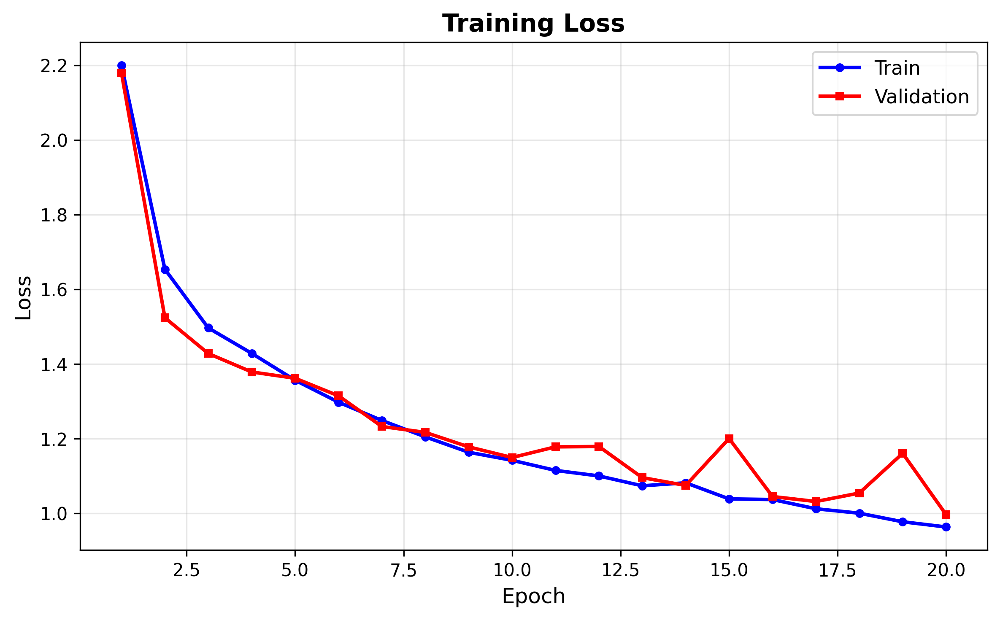

BEST MODEL (Epoch 20)
  Train Loss: 0.963941
  Val Loss:   0.996763
  Train MSE:  0.029031
  Val MSE:    0.029545
  Train Perceptual: 0.958135
  Val Perceptual:   0.990854

  Improvement from initial: 54.27%


In [47]:
plot_loss_and_metrics(history, loss_type="combined")

In [49]:
print("\n--- Audio Reconstructions from Perceptual-trained Model ---\n")
display_audio_comparisons(improved_model, test_loader, device, sample_rate=SAMPLE_RATE, n_samples=4)


--- Audio Reconstructions from Perceptual-trained Model ---

Sample 1/4 - Clip ID: 33162

🎵 Original Audio:



🔄 Reconstructed Audio:




Sample 2/4 - Clip ID: 470

🎵 Original Audio:



🔄 Reconstructed Audio:




Sample 3/4 - Clip ID: 207

🎵 Original Audio:



🔄 Reconstructed Audio:




Sample 4/4 - Clip ID: 204

🎵 Original Audio:



🔄 Reconstructed Audio:




Displayed 4 audio comparisons


By combining the two losses and increasing the model size we got a good metric performance in terms of MSE and perceptual metrics. However, perceptual quality of the reconstructed audio is still not good, with artifacts and noise present in the reconstructions. I'll say that results presented using the simple implementation of perceptual loss got better perceptual quality, than the results using the `auraloss` library.

As a final test, I'll train with the following settings:

*   Using the full dataset
*   Slightly reducing the DataAugmentation probability
*   Trying to use same parameters of the `multi_scale_stft_loss()` impelemation but with `auraloss` library.
*   Give more weight to the perceptual loss in the combined loss function, than MSE loss.

In [ ]:
class AugmentationChain(nn.Module):
    """Add a number of audio augmentaitons with probability p."""

    p = 0.5 # Changed from 0.75 to 0.5
    sr = 16000
    def __init__(self, **kwargs):
        super().__init__()
        self.chain = Compose(
            transforms=[
                Gain(p=self.p, output_type='tensor'),
                BandStopFilter(sample_rate=self.sr, p=self.p, output_type='tensor'),
                PitchShift(p=self.p, sample_rate=self.sr, output_type='tensor'),
                AddColoredNoise(p=self.p, output_type='tensor'),
                LowPassFilter(p=self.p, sample_rate=self.sr, min_cutoff_freq=400, output_type='tensor',),
            ]
            , output_type='tensor'
        )

    def forward(self, audio):
        return self.chain(audio.unsqueeze(1)).squeeze(1)

In [ ]:
def train_improved_autoencoder(
    model,
    device,
    train_loader,
    val_loader,
    num_epochs=20,
    learning_rate=1e-3,
    use_augmentation=True,
    loss_type='combined',  # 'mse', 'perceptual', or 'combined'
    alpha=1.0,  # weight for MSE loss
    beta=0.1,   # weight for perceptual loss (from auraloss)
    save_best_model=True,
    checkpoint_path='improved_autoencoder.pth'
):
    """
    Train improved audio autoencoder with data augmentation and combined loss function.

    :param model: ImprovedAudioAutoencoder model to train.
    :param device: Device to use for training (MPS, CPU, or GPU).
    :param train_loader: DataLoader for training data.
    :param val_loader: DataLoader for validation data.
    :param num_epochs: Number of training epochs.
    :param learning_rate: Learning rate for the optimizer.
    :param use_augmentation: Whether to apply data augmentation during training.
    :param loss_type: Type of loss function to use ('mse', 'perceptual', or 'combined').
    :param alpha: Weight for MSE loss (used when loss_type='combined').
    :param beta: Weight for perceptual loss (used when loss_type='combined').
    :param save_best_model: Whether to save the best model based on validation loss.
    :param checkpoint_path: Path to save the best model checkpoint.

    :return: history dictionary with training and validation losses.
    """
    
    # Move model to device
    model.to(device)
    
    # Initialize optimizer
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    
    # Define loss functions
    mse_criterion = nn.MSELoss()
    
    # Initialize auraloss Multi-Resolution STFT Loss with perceptual weighting
    auraloss_criterion = auraloss.freq.MultiResolutionSTFTLoss(
        fft_sizes=[512, 1024, 2048], # Changed
        hop_sizes=[128, 256, 512], # Changed
        win_lengths=[512, 1024, 2048], # Changed
        scale="mel",
        n_bins=128,
        sample_rate=SAMPLE_RATE,
        perceptual_weighting=True,
    ).to(device)
    
    # Initialize augmentation chain if requested
    augmentation = None
    if use_augmentation:
        augmentation = AugmentationChain()
        augmentation.to(device)
        augmentation.eval()  # Keep in eval mode during training
        print("Data augmentation enabled")

    # Initialize history
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_mse": [],
        "train_perceptual": [],
        "val_mse": [],
        "val_perceptual": []
    }

    # Track best validation loss for model saving
    best_val_loss = float('inf')
    best_epoch = 0

    for epoch in range(num_epochs):
        model.train()
        train_losses = []
        train_mse_losses = []
        train_perceptual_losses = []

        train_iter = iter(train_loader)
        train_pbar = tqdm(range(len(train_loader)), desc=f'Epoch {epoch+1}/{num_epochs} [Train]')
        for i in train_pbar:
            # Get batch
            batch = next(train_iter)
            audio = batch['audio'].to(device)
            
            # Apply augmentation if enabled
            if use_augmentation and augmentation is not None:
                with torch.no_grad():
                    audio = augmentation(audio)

            # Optimization step
            optimizer.zero_grad()

            # Forward pass
            recon_audio, _ = model(audio.unsqueeze(1))
            recon_audio = recon_audio.squeeze(1)
            
            # Calculate losses based on loss_type
            if loss_type == 'mse':
                loss = mse_criterion(recon_audio, audio)
                mse_loss = loss.item()
                perceptual_loss = 0.0
            elif loss_type == 'perceptual':
                loss = auraloss_criterion(recon_audio.unsqueeze(1), audio.unsqueeze(1))
                mse_loss = 0.0
                perceptual_loss = loss.item()
            elif loss_type == 'combined':
                mse_loss_val = mse_criterion(recon_audio, audio)
                perceptual_loss_val = auraloss_criterion(recon_audio.unsqueeze(1), audio.unsqueeze(1))
                
                # Combined loss with weighted sum
                loss = alpha * mse_loss_val + beta * perceptual_loss_val
                mse_loss = mse_loss_val.item()
                perceptual_loss = perceptual_loss_val.item()
            else:
                raise ValueError(f"Invalid loss_type: {loss_type}. Must be 'mse', 'perceptual', or 'combined'")
            
            # Backward pass and optimization
            loss.backward()
            optimizer.step()

            # Record losses
            train_losses.append(loss.item())
            train_mse_losses.append(mse_loss)
            train_perceptual_losses.append(perceptual_loss)
            
            # Update progress bar
            if loss_type == 'combined':
                train_pbar.set_postfix({
                    'loss': f'{loss.item():.4f}',
                    'mse': f'{mse_loss:.4f}',
                    'perc': f'{perceptual_loss:.4f}'
                })
            else:
                train_pbar.set_postfix({'loss': f'{loss.item():.4f}'})

        avg_train_loss = np.mean(train_losses)
        history['train_loss'].append(avg_train_loss)
        history['train_mse'].append(np.mean(train_mse_losses))
        history['train_perceptual'].append(np.mean(train_perceptual_losses))

        # Validation
        model.eval()
        val_losses = []
        val_mse_losses = []
        val_perceptual_losses = []

        with torch.no_grad():
            val_iter = iter(val_loader)
            val_pbar = tqdm(range(len(val_loader)), desc=f'Epoch {epoch+1}/{num_epochs} [Val]')
            for i in val_pbar:
                # Get batch
                batch = next(val_iter)
                audio = batch['audio'].to(device)
                
                # Forward pass (no augmentation during validation)
                recon_audio, _ = model(audio.unsqueeze(1))
                recon_audio = recon_audio.squeeze(1)
                
                # Always calculate both losses for monitoring
                mse_loss_val = mse_criterion(recon_audio, audio)
                perceptual_loss_val = auraloss_criterion(recon_audio.unsqueeze(1), audio.unsqueeze(1))
                
                # Select which loss to use for model selection based on loss_type
                if loss_type == 'mse':
                    loss = mse_loss_val
                elif loss_type == 'perceptual':
                    loss = perceptual_loss_val
                elif loss_type == 'combined':
                    loss = alpha * mse_loss_val + beta * perceptual_loss_val
                else:
                    raise ValueError(f"Invalid loss_type: {loss_type}. Must be 'mse', 'perceptual', or 'combined'")

                val_losses.append(loss.item())
                val_mse_losses.append(mse_loss_val.item())
                val_perceptual_losses.append(perceptual_loss_val.item())
                
                # Update progress bar
                if loss_type == 'combined':
                    val_pbar.set_postfix({
                        'loss': f'{loss.item():.4f}',
                        'mse': f'{mse_loss_val.item():.4f}',
                        'perc': f'{perceptual_loss_val.item():.4f}'
                    })
                else:
                    val_pbar.set_postfix({'loss': f'{loss.item():.4f}'})

        avg_val_loss = np.mean(val_losses)
        history['val_loss'].append(avg_val_loss)
        history['val_mse'].append(np.mean(val_mse_losses))
        history['val_perceptual'].append(np.mean(val_perceptual_losses))
        
        # Save best model based on validation loss
        if save_best_model and avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            best_epoch = epoch + 1
            torch.save({
                'epoch': epoch + 1,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'val_loss': avg_val_loss,
                'train_loss': avg_train_loss,
                'history': history,
                'config': {
                    'loss_type': loss_type,
                    'alpha': alpha,
                    'beta': beta,
                    'use_augmentation': use_augmentation,
                    'learning_rate': learning_rate
                }
            }, checkpoint_path)
            print(f'\n[Epoch {epoch+1}] Saved best model (val_loss: {avg_val_loss:.6f})')
    
    if save_best_model:
        print(f'\nTraining completed! Best model from epoch {best_epoch} with val_loss: {best_val_loss:.6f}')
        print(f'Model saved to: {checkpoint_path}')

    return history

Create the full training dataset, and training again. 

In [57]:
train_dataset = MagnaTagATuneDataset(
    annotation_file_path='./data/annotations_final.csv',
    split_file_path='./data/train_gt_mtt.tsv',
    audio_duration=AUDIO_DURATION,
    sample_rate=SAMPLE_RATE,
    subsample_factor=1.0
)

train_loader = DataLoader(
    train_dataset, 
    batch_size=128,
    shuffle=True,
    # num_workers=0,  # Set to 0 for Jupyter notebooks
    # pin_memory=True # Not working on MPS
)

# Train the improved model with combined loss and augmentation
improved_model = ImprovedAudioAutoencoder(
    input_length=train_dataset.n_samples, 
    bottleneck_size=512, 
    downsample=2,
    channels=8,
    channel_mult=2
)

# Train with combined loss and augmentation
history = train_improved_autoencoder(
    improved_model,
    device,
    train_loader,
    val_loader,
    num_epochs=20,
    learning_rate=1e-3,
    use_augmentation=True,
    loss_type='combined',
    alpha=0.1, 
    beta=1.0,  
    save_best_model=True,
    checkpoint_path='improved_autoencoder_2.pth'
)

Compression rate: 31.2X
Architecture: 5 encoder layers, 128 channels at bottleneck
Data augmentation enabled


Epoch 1/20 [Val]: 100%|██████████| 15/15 [00:15<00:00,  1.04s/it, loss=1.5110, mse=0.0445, perc=1.5065]



[Epoch 1] Saved best model (val_loss: 1.527278)


Epoch 2/20 [Val]: 100%|██████████| 15/15 [00:15<00:00,  1.04s/it, loss=1.4002, mse=0.0507, perc=1.3951]



[Epoch 2] Saved best model (val_loss: 1.353372)


Epoch 3/20 [Val]: 100%|██████████| 15/15 [00:15<00:00,  1.04s/it, loss=1.2399, mse=0.0503, perc=1.2348]


... (19 outputs left out)

Epoch 18/20 [Val]: 100%|██████████| 15/15 [00:15<00:00,  1.03s/it, loss=0.8310, mse=0.0615, perc=0.8248]



[Epoch 18] Saved best model (val_loss: 0.879553)


Epoch 20/20 [Val]: 100%|██████████| 15/15 [00:15<00:00,  1.04s/it, loss=1.0283, mse=0.0723, perc=1.0211]


Training completed! Best model from epoch 18 with val_loss: 0.879553
Model saved to: improved_autoencoder_2.pth


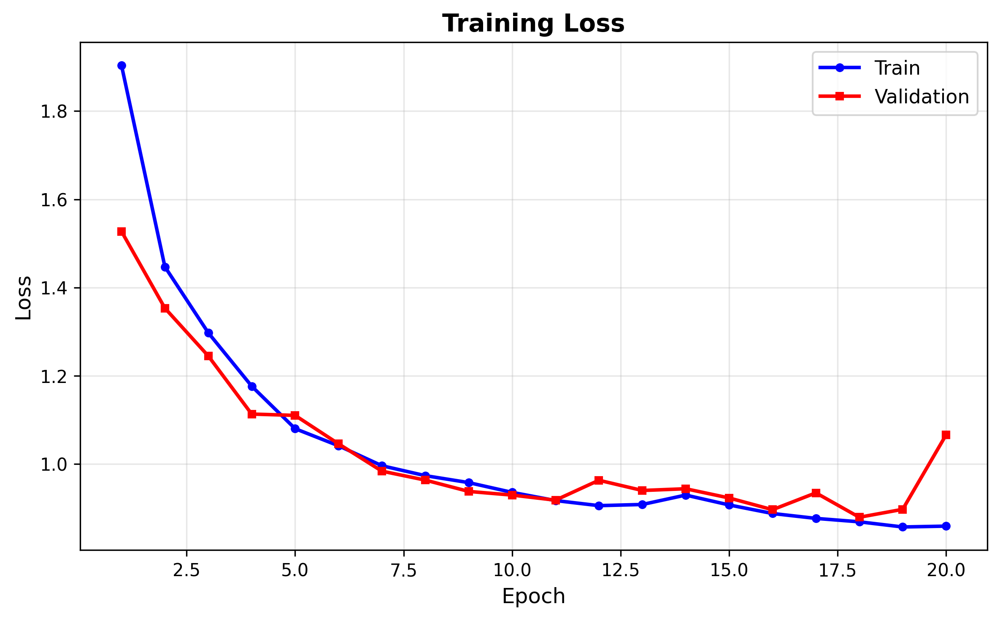

BEST MODEL (Epoch 18)
  Train Loss: 0.869229
  Val Loss:   0.879553
  Train MSE:  0.061881
  Val MSE:    0.065732
  Train Perceptual: 0.863041
  Val Perceptual:   0.872980

  Improvement from initial: 42.41%


In [58]:
plot_loss_and_metrics(history, loss_type="combined")

Load the best checkpointed model and evaluate its performance. 

In [92]:
# Initialize the model architecture
model = ImprovedAudioAutoencoder(
    input_length=SAMPLE_RATE,  # 1 second input
    bottleneck_size=512,
    downsample=2,
    channels=8,
    channel_mult=2
)

# Load the trained checkpoint
model, checkpoint = load_checkpoint(
    model, 
    'improved_autoencoder_2.pth',  # or 'improved_autoencoder_1.pth'
    device
)

print("\n--- Audio Reconstructions from Perceptual-trained Model ---\n")
display_audio_comparisons(model, test_loader, device, sample_rate=SAMPLE_RATE, n_samples=10)

Compression rate: 31.2X
Architecture: 5 encoder layers, 128 channels at bottleneck
Loaded checkpoint from epoch 18
Training loss: 0.869229
Validation loss: 0.879553
Model configuration: {'loss_type': 'combined', 'alpha': 0.1, 'beta': 1.0, 'use_augmentation': True, 'learning_rate': 0.001}

--- Audio Reconstructions from Perceptual-trained Model ---

Loaded checkpoint from epoch 18
Training loss: 0.869229
Validation loss: 0.879553
Model configuration: {'loss_type': 'combined', 'alpha': 0.1, 'beta': 1.0, 'use_augmentation': True, 'learning_rate': 0.001}

--- Audio Reconstructions from Perceptual-trained Model ---

Sample 1/10 - Clip ID: 33418

🎵 Original Audio:
Sample 1/10 - Clip ID: 33418

🎵 Original Audio:



🔄 Reconstructed Audio:




Sample 2/10 - Clip ID: 35

🎵 Original Audio:



🔄 Reconstructed Audio:




Sample 3/10 - Clip ID: 33566

🎵 Original Audio:



🔄 Reconstructed Audio:


... (11 outputs left out)


🔄 Reconstructed Audio:




Sample 10/10 - Clip ID: 33006

🎵 Original Audio:



🔄 Reconstructed Audio:




Displayed 10 audio comparisons


**Comment:**

By combining the two losses, increasing the model size, and training with the full dataset we got a good metric performance in terms of MSE and perceptual metrics. Compared to previous experiments, perceptual quality of the reconstructed audio is improved, still some artifacts and noise are present in the reconstructions but less noticeable than before. 

In terms of MSE, the model performs well, but still less than if we only used MSE loss. However, the trade-off is worth it as the perceptual quality is significantly better. 

Everything will depend on the downstream task, we may choose different training objectives. However, for audio reconstruction, incorporating a perceptual loss is critical for preserving noticeable details. Using only MSE leads to reconstructions that sounds noisy or overly smooth and fail to capture fine structures that are important to human.

I conclude that using a combination of MSE and perceptual loss, along with data augmentation and a larger model capacity, leads to improved performance in audio reconstruction tasks. Further fine-tuning of the loss weights, perceptual loss parameters, and model architecture could yield better results.

## Evaluate Perceptually on Longer audios and Compression

Finally, I will evaluate the trained autoencoder on longer audio clips to assess its performance in reconstructing more complex audio signals. Using non-overlapping snippets from longer audio clips, I will pass them through the autoencoder and reconstruct the full audio by concatenating the reconstructed snippets. 

In [96]:
def encode_decode_long_audio(model, audio_path, device, window_size=16000, sample_rate=16000, play_audio=True):
    """
    Encode and decode a long audio file using non-overlapping windows.
    
    Args:
        model: Trained autoencoder model
        audio_path: Path to the audio file
        device: Device to run the model on
        window_size: Size of each window in samples (default: 16000 = 1 second at 16kHz)
        sample_rate: Target sample rate (default: 16000)
        play_audio: Whether to play the original and reconstructed audio (default: True)
    
    Returns:
        original_audio: Original audio as numpy array
        reconstructed_audio: Reconstructed audio as numpy array
    """

    model.eval()
    
    # Load the audio file
    audio, sr = torchaudio.load(audio_path)
    
    # Resample if necessary
    if sr != sample_rate:
        resampler = torchaudio.transforms.Resample(sr, sample_rate)
        audio = resampler(audio)
    
    # Convert to mono if stereo
    if audio.shape[0] > 1:
        audio = torch.mean(audio, dim=0, keepdim=True)
    
    # Remove channel dimension for processing
    audio = audio.squeeze(0)
    original_length = audio.shape[0]
    
    print(f"Original audio length: {original_length} samples ({original_length/sample_rate:.2f} seconds)")
    
    # Pad audio to make it divisible by window_size
    n_windows = (original_length + window_size - 1) // window_size
    padded_length = n_windows * window_size
    
    if padded_length > original_length:
        padding = padded_length - original_length
        audio = torch.nn.functional.pad(audio, (0, padding))
        print(f"Padded to {padded_length} samples ({n_windows} windows of {window_size} samples)")
    
    # Split into non-overlapping windows
    audio_windows = audio.view(n_windows, window_size)
    
    # Process each window through the autoencoder
    reconstructed_windows = []
    
    with torch.no_grad():
        for i in tqdm(range(n_windows), desc="Processing windows"):
            window = audio_windows[i:i+1].to(device)
            
            # Encode and decode
            recon_window, _ = model(window.unsqueeze(1))
            reconstructed_windows.append(recon_window.squeeze().cpu())
    
    # Concatenate all reconstructed windows
    reconstructed_audio = torch.cat(reconstructed_windows, dim=0)
    
    # Trim back to original length
    reconstructed_audio = reconstructed_audio[:original_length]
    
    print(f"Reconstructed audio length: {reconstructed_audio.shape[0]} samples")
    
    # Convert to numpy for playback
    original_audio_np = audio[:original_length].numpy()
    reconstructed_audio_np = reconstructed_audio.numpy()
    
    if play_audio:
        print("\n Original Audio:")
        display(ipd.Audio(original_audio_np, rate=sample_rate))
        
        print("\n Reconstructed Audio:")
        display(ipd.Audio(reconstructed_audio_np, rate=sample_rate))
    
    return original_audio_np, reconstructed_audio_np

Let's load a full 30 audios file and reconstruct it using non-overlapping 1-second windows.

In [97]:
# Get a sample audio file from the test dataset (full 30 seconds)
sample_clip = test_dataset.data.iloc[0]
audio_path = f"./data/mp3/{sample_clip['mp3_path']}"

print(f"Selected audio file: {audio_path}")
print(f"Clip ID: {sample_clip['clip_id']}")

# Encode and decode the long audio
original, reconstructed = encode_decode_long_audio(
    model=model,
    audio_path=audio_path,
    device=device,
    window_size=SAMPLE_RATE,  # 1 second windows
    sample_rate=SAMPLE_RATE,
    play_audio=True
)

Selected audio file: ./data/mp3/f/american_bach_soloists-j_s__bach_solo_cantatas-01-bwv54__i_aria-30-59.mp3
Clip ID: 2
Original audio length: 465984 samples (29.12 seconds)
Padded to 480000 samples (30 windows of 16000 samples)


Processing windows: 100%|██████████| 30/30 [00:00<00:00, 59.19it/s]

Reconstructed audio length: 465984 samples

 Original Audio:



 Reconstructed Audio:


In [102]:
# Get a sample audio file from the test dataset (full 30 seconds)
sample_clip = test_dataset.data.iloc[50]
audio_path = f"./data/mp3/{sample_clip['mp3_path']}"

print(f"Selected audio file: {audio_path}")
print(f"Clip ID: {sample_clip['clip_id']}")

# Encode and decode the long audio
original, reconstructed = encode_decode_long_audio(
    model=model,
    audio_path=audio_path,
    device=device,
    window_size=SAMPLE_RATE,  # 1 second windows
    sample_rate=SAMPLE_RATE,
    play_audio=True
)

Selected audio file: ./data/mp3/f/chris_juergensen-big_bad_sun-07-revelation-30-59.mp3
Clip ID: 33004
Original audio length: 465984 samples (29.12 seconds)
Padded to 480000 samples (30 windows of 16000 samples)


Processing windows: 100%|██████████| 30/30 [00:00<00:00, 146.06it/s]

Reconstructed audio length: 465984 samples

 Original Audio:



 Reconstructed Audio:


Using a FreeSound audio clip: https://freesound.org/people/bainmack/sounds/621165/

In [98]:
# Get a sample audio file from the test dataset (full 30 seconds)
audio_path = "621165__bainmack__rock_song_short16.wav"

print(f"Selected audio file: {audio_path}")
print(f"Clip ID: {sample_clip['clip_id']}")

# Encode and decode the long audio
original, reconstructed = encode_decode_long_audio(
    model=model,
    audio_path=audio_path,
    device=device,
    window_size=SAMPLE_RATE,  # 1 second windows
    sample_rate=SAMPLE_RATE,
    play_audio=True
)

Selected audio file: 621165__bainmack__rock_song_short16.wav
Clip ID: 2
Original audio length: 712000 samples (44.50 seconds)
Padded to 720000 samples (45 windows of 16000 samples)


Processing windows: 100%|██████████| 45/45 [00:00<00:00, 80.49it/s] 

Reconstructed audio length: 712000 samples

 Original Audio:



 Reconstructed Audio:


The reconstructed audio still sounds bad, with noticeable noise and loss of quality. But we hear continuity in the reconstructed audio, no abrupt changes between snippets. Further improvements could be made in parameters, and training time to enhance the reconstruction quality.